# **Studi Kasus: Deteksi dan Klasifikasi Penyebab Deforestasi Menggunakan Machine Learning di Google Colab**

Hutan tropis memiliki peran penting dalam menyerap karbon, menjaga keanekaragaman hayati, dan mengatur siklus air. Namun, keberadaan hutan semakin terancam oleh aktivitas manusia, seperti pembukaan lahan pertanian, pembangunan jalan, pembalakan, dan pertambangan, serta gangguan alami seperti kebakaran dan banjir. Untuk membantu memantau perubahan tutupan hutan, diperlukan sistem yang dapat mengidentifikasi area yang mengalami deforestasi sekaligus memperkirakan penyebabnya secara lebih efisien. Salah satu pendekatan yang dapat digunakan adalah menggabungkan citra satelit Sentinel-1 yang menggunakan radar dan Sentinel-2 yang menggunakan sensor optik, kemudian memanfaatkan Machine Learning untuk menganalisis perubahan karakteristik wilayah. Data radar bermanfaat di daerah tropis karena dapat digunakan dalam kondisi berawan, sedangkan citra optik menyediakan informasi spektral yang membantu membedakan vegetasi dan jenis tutupan lahan.

Dalam studi kasus ini, mahasiswa diminta membuat prototipe klasifikasi penyebab perubahan tutupan hutan menggunakan Python di Google Colab. Dataset simulasi memuat sejumlah indikator, seperti perubahan tutupan vegetasi, perubahan pantulan radar, kedekatan dengan jalan, dan perubahan aktivitas lahan. Algoritma Random Forest digunakan untuk mengklasifikasikan perubahan tersebut ke dalam beberapa kategori, seperti pertanian, pembangunan jalan, pembalakan, pertambangan, dan gangguan alami. Proses pengerjaan mencakup pembuatan dataset, pemeriksaan data, pemisahan data training dan testing, pelatihan model, evaluasi akurasi, serta visualisasi hasil klasifikasi. Prototipe ini menggambarkan konsep dasar sistem pemantauan deforestasi berbantuan AI, tetapi tidak menggunakan citra satelit Sentinel yang sebenarnya. Oleh karena itu, hasil klasifikasi hanya untuk pembelajaran dan belum dapat digunakan sebagai bukti deforestasi atau dasar penindakan terhadap aktivitas ilegal.

=== DATASET SIMULASI ===


,perubahan_vegetasi,perubahan_radar,jarak_jalan_km,intensitas_perubahan_lahan,penyebab
0,0.480286,0.392798,1.237451,0.746806,Pertambangan
1,0.439990,0.429624,0.967530,0.271433,Pembalakan
2,0.408234,0.684955,2.114618,0.306170,Pembalakan
3,0.173362,0.221697,1.097037,0.829584,Pertambangan
4,0.409910,0.359944,0.235330,0.989502,Pertanian
5,0.552985,0.691615,1.273555,0.629970,Pembalakan
6,0.425250,0.207959,4.768807,0.637973,Gangguan Alami
7,0.421846,0.348836,0.342117,0.620076,Pembangunan Jalan
8,0.298071,0.113755,1.827709,0.777634,Pertambangan
9,0.224684,0.308027,1.138750,0.755456,Pertambangan


Jumlah data: 300

Distribusi kategori:
penyebab
Gangguan Alami       78
Pembangunan Jalan    61
Pembalakan           60
Pertambangan         52
Pertanian            49
Name: count, dtype: int64

=== PEMERIKSAAN DATA ===
Nilai kosong: 0
Baris duplikat: 0

Data training: 225
Data testing: 75

=== HASIL EVALUASI ===
Akurasi model: 77.33%

Classification Report:
                   precision    recall  f1-score   support

   Gangguan Alami       0.82      0.70      0.76        20
       Pembalakan       0.86      0.80      0.83        15
Pembangunan Jalan       0.79      1.00      0.88        15
     Pertambangan       0.83      0.77      0.80        13
        Pertanian       0.54      0.58      0.56        12

         accuracy                           0.77        75
        macro avg       0.77      0.77      0.77        75
     weighted avg       0.78      0.77      0.77        75



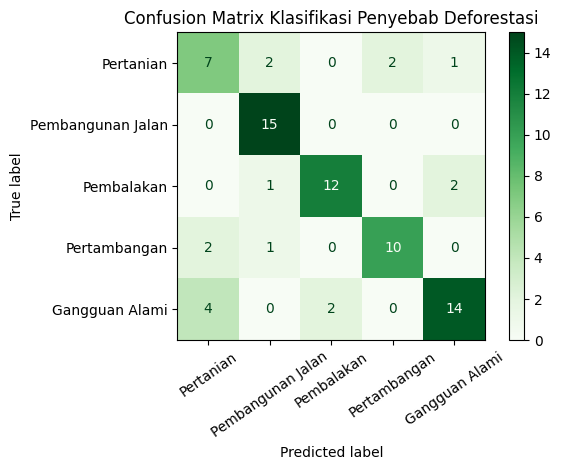


=== KEPENTINGAN FITUR ===


,fitur,kepentingan
2,jarak_jalan_km,0.405947
3,intensitas_perubahan_lahan,0.257572
0,perubahan_vegetasi,0.182691
1,perubahan_radar,0.153789


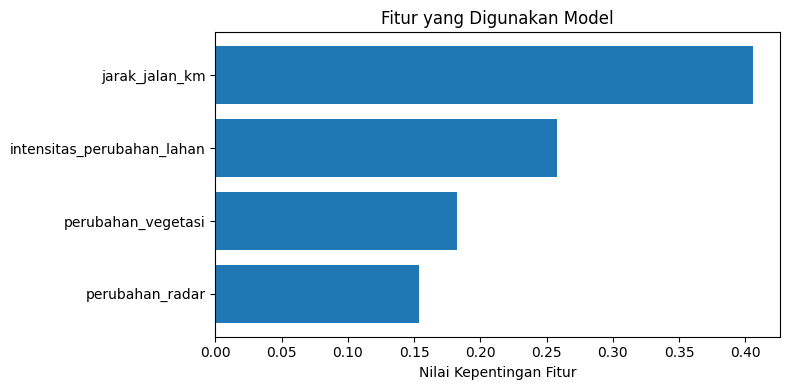


=== HASIL PREDIKSI AREA BARU ===


,perubahan_vegetasi,perubahan_radar,jarak_jalan_km,intensitas_perubahan_lahan,prediksi_penyebab,keyakinan_model
0,0.25,0.30,0.3,0.90,Pertanian,0.54
1,0.65,0.55,2.0,0.40,Pembalakan,0.79
2,0.35,0.25,1.5,0.85,Pertambangan,0.80



PENTING: Data ini hanya simulasi pembelajaran. Prediksi bukan bukti deforestasi atau aktivitas ilegal. Keyakinan model bukan jaminan kebenaran prediksi.


In [1]:

# STUDI KASUS:
# Klasifikasi Penyebab Deforestasi Menggunakan Machine Learning
# Google Colab + Random Forest
#
# Catatan: Dataset sepenuhnya sintetis, bukan citra satelit asli.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Membuat dataset simulasi
np.random.seed(42)
jumlah_data = 300

kategori = [
    "Pertanian",
    "Pembangunan Jalan",
    "Pembalakan",
    "Pertambangan",
    "Gangguan Alami"
]

# Membuat sampel dengan karakteristik yang disimulasikan
data = []

for i in range(jumlah_data):
    penyebab = np.random.choice(kategori)

    if penyebab == "Pertanian":
        vegetasi = np.random.uniform(0.2, 0.6)
        radar = np.random.uniform(0.2, 0.6)
        jarak_jalan = np.random.uniform(0.1, 3)
        perubahan_lahan = np.random.uniform(0.6, 1.0)

    elif penyebab == "Pembangunan Jalan":
        vegetasi = np.random.uniform(0.3, 0.7)
        radar = np.random.uniform(0.3, 0.8)
        jarak_jalan = np.random.uniform(0.0, 0.5)
        perubahan_lahan = np.random.uniform(0.4, 0.9)

    elif penyebab == "Pembalakan":
        vegetasi = np.random.uniform(0.4, 0.8)
        radar = np.random.uniform(0.2, 0.7)
        jarak_jalan = np.random.uniform(0.2, 2.5)
        perubahan_lahan = np.random.uniform(0.2, 0.7)

    elif penyebab == "Pertambangan":
        vegetasi = np.random.uniform(0.1, 0.5)
        radar = np.random.uniform(0.1, 0.5)
        jarak_jalan = np.random.uniform(0.1, 2)
        perubahan_lahan = np.random.uniform(0.7, 1.0)

    else:  # Gangguan alami
        vegetasi = np.random.uniform(0.2, 0.7)
        radar = np.random.uniform(0.2, 0.8)
        jarak_jalan = np.random.uniform(1, 5)
        perubahan_lahan = np.random.uniform(0.3, 0.9)

    data.append([
        vegetasi, radar, jarak_jalan,
        perubahan_lahan, penyebab
    ])

df = pd.DataFrame(data, columns=[
    "perubahan_vegetasi",
    "perubahan_radar",
    "jarak_jalan_km",
    "intensitas_perubahan_lahan",
    "penyebab"
])

print("=== DATASET SIMULASI ===")
display(df.head(10))
print("Jumlah data:", len(df))
print("\nDistribusi kategori:")
print(df["penyebab"].value_counts())

# 2. Memeriksa kualitas data
print("\n=== PEMERIKSAAN DATA ===")
print("Nilai kosong:", df.isnull().sum().sum())
print("Baris duplikat:", df.duplicated().sum())

# 3. Menentukan fitur dan target
fitur = [
    "perubahan_vegetasi",
    "perubahan_radar",
    "jarak_jalan_km",
    "intensitas_perubahan_lahan"
]

X = df[fitur]
y = df["penyebab"]

# 4. Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nData training:", len(X_train))
print("Data testing:", len(X_test))

# 5. Melatih model Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# 6. Mengevaluasi model
prediksi = model.predict(X_test)

akurasi = accuracy_score(y_test, prediksi)

print("\n=== HASIL EVALUASI ===")
print(f"Akurasi model: {akurasi:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, prediksi, zero_division=0))

# 7. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    prediksi,
    labels=kategori,
    xticks_rotation=35,
    cmap="Greens"
)

plt.title("Confusion Matrix Klasifikasi Penyebab Deforestasi")
plt.tight_layout()
plt.show()

# 8. Melihat tingkat kepentingan fitur
kepentingan = pd.DataFrame({
    "fitur": fitur,
    "kepentingan": model.feature_importances_
}).sort_values("kepentingan", ascending=False)

print("\n=== KEPENTINGAN FITUR ===")
display(kepentingan)

plt.figure(figsize=(8, 4))
plt.barh(
    kepentingan["fitur"],
    kepentingan["kepentingan"]
)
plt.xlabel("Nilai Kepentingan Fitur")
plt.title("Fitur yang Digunakan Model")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 9. Simulasi prediksi area baru
area_baru = pd.DataFrame({
    "perubahan_vegetasi": [0.25, 0.65, 0.35],
    "perubahan_radar": [0.30, 0.55, 0.25],
    "jarak_jalan_km": [0.3, 2.0, 1.5],
    "intensitas_perubahan_lahan": [0.9, 0.4, 0.85]
})

hasil_prediksi = model.predict(area_baru)
probabilitas = model.predict_proba(area_baru).max(axis=1)

area_baru["prediksi_penyebab"] = hasil_prediksi
area_baru["keyakinan_model"] = np.round(probabilitas, 3)

print("\n=== HASIL PREDIKSI AREA BARU ===")
display(area_baru)

print(
    "\nPENTING: Data ini hanya simulasi pembelajaran. "
    "Prediksi bukan bukti deforestasi atau aktivitas ilegal. "
    "Keyakinan model bukan jaminan kebenaran prediksi."
)


Berdasarkan studi kasus klasifikasi penyebab deforestasi menggunakan Machine Learning di Google Colab, dapat disimpulkan bahwa teknologi AI berpotensi membantu proses pemantauan hutan dengan menganalisis pola perubahan tutupan lahan dan mengelompokkan dugaan penyebabnya. Melalui algoritma Random Forest, mahasiswa dapat mempelajari tahapan pengolahan data, pembagian data training dan testing, pelatihan model, evaluasi kinerja, serta interpretasi hasil prediksi. Integrasi data radar Sentinel-1 dan citra optik Sentinel-2 dalam pengembangan lebih lanjut dapat memberikan informasi yang saling melengkapi, terutama untuk pemantauan wilayah tropis yang sering tertutup awan.

Meskipun demikian, keandalan sistem sangat bergantung pada kualitas data, ketepatan label, dan kemampuan model membedakan pola perubahan yang serupa. Gangguan alami, pembalakan, pertanian, dan pertambangan dapat memiliki karakteristik yang tumpang tindih sehingga hasil klasifikasi perlu diverifikasi sebelum digunakan untuk mengambil keputusan. Oleh karena itu, AI sebaiknya dimanfaatkan sebagai alat bantu pemantauan dan penentuan lokasi pemeriksaan, bukan sebagai satu-satunya dasar untuk menyimpulkan penyebab deforestasi atau menetapkan adanya aktivitas ilegal. Studi kasus ini menunjukkan bagaimana Machine Learning dapat mendukung perlindungan lingkungan apabila dikembangkan dengan data yang valid, evaluasi yang memadai, dan penerapan yang bertanggung jawab.